# BP growth validation: single-generation and multigeneration normalized BP

Run all cells in order from the repository root. By default this notebook **replots four figures from bundled, verified numeric measurements** in `plot_data/bp_growth/`. It calls the original Matplotlib plotting code and does not load existing figure images.

The single-generation cache contains 100,000 roots in each ordinary case and **30,000 roots in each of A, critical, and B** (790,000 total). These historical measurements have the correct endpoints and seed rules; they are not the current 200,000-path configuration. The multigeneration cache is the original completed **main** experiment: M=20,000, 12 generations, 10 independent runs for each of A/B, amplitude 1e-4. Its independent-run trajectories are included.

`PROVENANCE.json` records original paths, settings, SHA-256 hashes, and checks against all original NPZ arrays. No samples from the 30k and 200k campaigns are pooled. Outputs are saved under `outputs/bp_growth_validation/`.

To generate a new experiment, set `USE_CACHED_PLOT_DATA=False` and enable `RUN_ONE_GENERATION` and/or `RUN_MULTIGENERATION`. The original simulation algorithms, seeds, 100k/200k single-generation sizes and main multigeneration settings remain available below. New runs use timestamped output directories.

Scope: finite-depth responses on independent Poisson local trees for balanced planted partitions with label-independent boundary noise. Finite-graph overlap and EM are not computed. Dependencies: Python >= 3.10, NumPy, Matplotlib, SciPy, and tqdm.


## 1. Parameters and run controls

`K=4`, `C0=10`, `SIGNAL=0.5`, and the A/B construction follow the original experiment. `PATH_ROOTS=200_000` controls only the original single-generation experiment, **not the multigeneration population**.

| Multigeneration mode `MG_MODE` | Population M | Generations L | Independent runs R | Perturbation amplitude |
|---|---:|---:|---:|---|
| `pilot` | 2,000 | 4 | 3 | 1e-4 |
| `main` | 20,000 | 12 | 10 | 1e-4 |
| `amplitude_check` | 20,000 | 12 | 5 | 1e-3, 1e-4, 1e-5 (paired) |
| `population_check` | 5,000 / 20,000 / 80,000 | 12 | 5 | 1e-4 |
| `custom` | `MG_CUSTOM_*` below | Set below | Set below | Set below |

The two control modes run separately from `main`. Their random streams differ from the main experiment and cannot be pooled as paired observations. The main experiment tests A/B by default; add `"path_critical"` to `MG_CASE_NAMES` to include the critical point.

Sections 6–7 load the historical 30k-path cache by default. With `USE_CACHED_PLOT_DATA=False`, they run only when `RUN_ONE_GENERATION=True`. In the original experiment, `PILOT=False` uses 10 settings and 1,300,000 root neighborhoods; `PILOT=True` uses 17,000 neighborhoods. Reusing parameters and seeds reproduces the same experiment rather than adding independent samples. The pilot checks the workflow; amplitude and population checks are needed to assess numerical accuracy.

In [1]:
import csv
import itertools
import json
import math
import platform
import sys
import time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt

K, C0, SIGNAL = 4, 10.0, 0.5

# ---- Original single-generation experiment: retained, skipped by default ----
USE_CACHED_PLOT_DATA = True  # Default: redraw every figure from verified numeric data.
CACHE_ROOT = Path('plot_data') / 'bp_growth'
PLOT_OUTPUT_ROOT = Path('outputs') / 'bp_growth_validation'
RUN_ONE_GENERATION = False  # Enable explicitly after setting USE_CACHED_PLOT_DATA=False.
AMPLITUDES = (1e-3, 1e-4, 1e-5)
SEED = 2026091801
PILOT = False
ORDINARY_ROOTS = 100_000
PATH_ROOTS = 200_000
RUN_TAG = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = PLOT_OUTPUT_ROOT / 'single_generation' / ('pilot' if PILOT else 'full') / RUN_TAG
ONE_GENERATION_SOURCE_LABEL = 'NEW RUN'

# ---- Multigeneration experiment: start with pilot; switch to main for the main run ----
RUN_MULTIGENERATION = False  # Enable explicitly for a fresh campaign.
MG_MODE = "main"     # "main" / "amplitude_check" / "population_check" / "custom"
MG_CASE_NAMES = ("path_A", "path_B")  # Optionally add "path_critical".
MG_SEED = 2026092001
MG_BATCH_SIZE = 256
MG_BOOTSTRAP_SAMPLES = 2000
MG_OUTPUT_ROOT = PLOT_OUTPUT_ROOT / 'multigeneration'
MG_RUN_CHECKS = True
MG_SAVE_ROOT_RESPONSES = True   # Save each particle's squared response at every depth for auditing, not as independent replicates.
MG_SAVE_LAST_POPULATION = True  # Save the final complete positive/negative messages.

# Used only when MG_MODE="custom":
MG_CUSTOM_POPULATION = 20_000
MG_CUSTOM_DEPTH = 12
MG_CUSTOM_REPEATS = 10
MG_CUSTOM_AMPLITUDES = (1e-4,)

print(f'One generation: {RUN_ONE_GENERATION}; multi-generation: {RUN_MULTIGENERATION}; mode={MG_MODE}')


One generation: False; multi-generation: False; mode=main


## 2. Complete BP update

The factor kernel retains both root–child and child–child contributions:
$$F_f(a)=\sum_j\sum_b c_{ab}q_j(b)
+\sum_{j<k}\sum_{b,c}c_{bc}q_j(b)q_k(c).$$
Although independent of the root label $a$, the second term changes the normalized response. The variable update multiplies the prior by all incident factor messages and normalizes. In this symmetric setting, the nonedge external field is label-independent and cancels under normalization.

In [2]:
def factor_kernel(messages, affinity):
    """Unnormalized observed-factor message for each independent factor.

    messages[f,j,b] is child j's probability of label b. For root label a:
      F_f(a) = sum_j sum_b C_ab q_j(b)
             + sum_{j<k} sum_{b,c} C_bc q_j(b) q_k(c).
    The second term, although independent of a, MUST be retained before
    normalization. A common multiplicative layer scale cancels afterwards.
    """
    summed = messages.sum(axis=1)
    pair_sum = .5 * (np.sum((summed @ affinity) * summed, axis=1)
                      - np.sum((messages @ affinity) * messages, axis=(1, 2)))
    return summed @ affinity.T + pair_sum[:, None]


def root_normalize(log_factors, prior):
    """Full variable update: prior times product of incoming factor messages.

    In this balanced symmetric tree experiment the nonedge external field
    is label independent and cancels upon normalization. Parameters are fixed.
    """
    log_weight = log_factors + np.log(prior)
    log_weight -= log_weight.max(axis=-1, keepdims=True)
    weight = np.exp(log_weight)
    return weight / weight.sum(axis=-1, keepdims=True)


def affinity_matrix():
    # Mean row affinity is c0; epsilon=c_out/c_in=1/5.
    c = np.full((K, K), C0 * (1 - SIGNAL))
    np.fill_diagonal(c, C0 * (1 + (K - 1) * SIGNAL))
    return c


## 3. Measurements on independent local trees

Independently sample root-factor counts for each order, generate each child-message perturbation, and perform the complete factor and variable updates. `simulate()` does not call the theoretical growth formula. The original `batch_size=256` is retained; changing it can change the order of random draws.

In [3]:
def simulate(orders, nus, roots, seed, batch_size=256):
    """Generate independent local neighborhoods and evaluate full BP.

    Each child direction is independent, centered, isotropic on sum(x)=0,
    and has norm one. The +/- runs share graph and directions. Different
    amplitudes are also paired; they are not independent repetitions.
    """
    rng=np.random.default_rng(seed)
    c=affinity_matrix()
    prior=np.full(K,1/K)
    samples=np.zeros((roots,len(AMPLITUDES)))
    counts=np.zeros((roots,len(orders)),dtype=np.int32)
    direction_mean=np.zeros(K)
    number_directions=0
    start_time=time.perf_counter()
    for offset in range(0,roots,batch_size):
        n=min(batch_size,roots-offset)
        log_messages=np.zeros((len(AMPLITUDES),2,n,K))
        for layer,(d,nu) in enumerate(zip(orders,nus)):
            z=rng.poisson(nu,size=n)
            counts[offset:offset+n,layer]=z
            factor_roots=np.repeat(np.arange(n),z)
            nf=len(factor_roots)
            if not nf:
                continue
            xi=rng.normal(size=(nf,d-1,K))
            xi-=xi.mean(axis=-1,keepdims=True)
            xi/=np.linalg.norm(xi,axis=-1,keepdims=True)
            direction_mean+=xi.sum(axis=(0,1))
            number_directions+=nf*(d-1)
            for ai,amplitude in enumerate(AMPLITUDES):
                for si,sign in enumerate((1,-1)):
                    incoming=prior+sign*amplitude*xi
                    factors=factor_kernel(incoming,c)
                    factors/=factors.sum(axis=-1,keepdims=True)
                    log_factors=np.log(factors)
                    for label in range(K):
                        log_messages[ai,si,:,label]+=np.bincount(
                            factor_roots,weights=log_factors[:,label],minlength=n)
        q=root_normalize(log_messages,prior)
        for ai,amplitude in enumerate(AMPLITUDES):
            response=(q[ai,0]-q[ai,1])/(2*amplitude)
            samples[offset:offset+n,ai]=np.sum(response**2,axis=-1)
        completed=offset+n
        if completed%10240==0 or completed==roots:
            print(f'  {completed}/{roots} roots, {time.perf_counter()-start_time:.1f} s',flush=True)
    assert np.isfinite(samples).all() and (samples>=0).all()
    return samples,counts,dict(elapsed_seconds=time.perf_counter()-start_time,
                              child_messages=number_directions,
                              direction_component_mean=(direction_mean/number_directions).tolist())


def summarize(samples):
    result=[]
    for ai,amp in enumerate(AMPLITUDES):
        x=samples[:,ai]
        mean=float(x.mean())
        se=float(x.std(ddof=1)/math.sqrt(len(x)))
        result.append(dict(amplitude=amp, mean=mean, standard_error=se,
                           ci95_low=mean-1.96*se, ci95_high=mean+1.96*se))
    paired=(samples[:,0]-samples[:,-1])
    return result,dict(mean_difference_1e3_minus_1e5=float(paired.mean()),
                       paired_standard_error=float(paired.std(ddof=1)/math.sqrt(len(paired))),
                       relative_difference=float(paired.mean()/samples[:,-1].mean()))


## 4. Theoretical references and experiment settings

The order-resolved prediction is $G=\sum_d\nu_d(d-1)(\chi_d\lambda)^2$, with $\chi_d=2/[d(d-1)]$.
The geometric aggregate is $G_{\rm agg}=\bar k_h(F-1)\lambda^2\exp(2\sum_dP_E(d)\log\chi_d)$.

The 10 settings include a second-order baseline; mixtures $\{2,3\}$, $\{2,20\}$, and $\{2,50\}$ with their corresponding isolated higher-order layers; and A, the theoretical critical point, and B on the matched-summary path. Theory sets the critical point and provides comparisons after measurement; it does not generate the responses.

A/B names follow the paper's definitions. The right endpoint is always `path_B`, `t=1`; the single-generation path is ordered A, critical, B.

In [4]:
def predictions(orders, nus):
    """Analytical comparison only; not called by simulate()."""
    d = np.asarray(orders, dtype=float)
    nu = np.asarray(nus, dtype=float)
    chi = 2/(d*(d-1))
    p_e = (nu/d)/np.sum(nu/d)
    p_i = nu/nu.sum()
    branch_count = nu*(d-1)
    total_branch = branch_count.sum()
    p_b = branch_count/total_branch
    p_v = branch_count*chi**2/np.sum(branch_count*chi**2)
    f = float(np.sum(p_e*d))
    g = float(np.sum(branch_count*(SIGNAL*chi)**2))
    gagg = float(nu.sum()*(f-1)*SIGNAL**2*np.exp(2*np.sum(p_e*np.log(chi))))
    delta_b = float(np.log(total_branch/(nu.sum()*(f-1))))
    delta_j = float(np.log(np.sum(p_b*chi**2))-2*np.sum(p_b*np.log(chi)))
    delta_w = float(2*np.sum((p_b-p_e)*np.log(chi)))
    kl_j = float(np.sum(p_b*np.log(p_b/p_v)))
    kl_w = float(-2*np.sum((p_b-p_e)*np.log(p_b/p_e)))
    log_ratio = math.log(g/gagg)
    assert abs(log_ratio-delta_b-delta_j-delta_w) < 1e-12
    assert abs(delta_j-kl_j) < 1e-12 and abs(delta_w-kl_w) < 1e-12
    assert delta_b > -1e-12 and delta_j > -1e-12 and delta_w < 1e-12
    return dict(G=g, G_aggregate=gagg, mean_incidence=float(nu.sum()),
                mean_branches=float(total_branch), F=f,
                P_E=p_e.tolist(), P_I=p_i.tolist(), P_B=p_b.tolist(), P_V=p_v.tolist(),
                delta_B=delta_b, Delta_J=delta_j, Delta_W=delta_w, log_ratio=log_ratio)


def cases(pilot):
    result = []
    ordinary_n = 2000 if pilot else ORDINARY_ROOTS
    path_n = 1000 if pilot else PATH_ROOTS
    result.append(dict(name='pair_only', orders=[2], nus=[10.0], roots=ordinary_n))
    for d in (3, 20, 50):
        result.append(dict(name=f'mixture_2_{d}', orders=[2,d],
                           nus=[10.0,10.0/(d-1)], roots=ordinary_n))
        result.append(dict(name=f'isolated_{d}', orders=[d], nus=[10.0/(d-1)], roots=ordinary_n))
    z=(3*math.log(6)-math.log(28))/(7*math.log(6)-math.log(120))
    v=np.array([6*z-2,3-7*z,-1,z])
    p_a=.25+(49/200)*v
    p_b=.25-49/(200*v[1])*v
    path_orders=np.array([2,4,8,16])
    path_nus=lambda p: 50*path_orders*p/7.5
    ga=predictions(path_orders,path_nus(p_a))['G']
    gb=predictions(path_orders,path_nus(p_b))['G']
    tc=(1-ga)/(gb-ga)
    for name,t in [('A',0.0),('critical',tc),('B',1.0)]:
        p=(1-t)*p_a+t*p_b
        result.append(dict(name=f'path_{name}', orders=path_orders.tolist(),
                           nus=path_nus(p).tolist(), roots=path_n, path_t=t))
    for i, case in enumerate(result):
        case['seed']=SEED+i*1009
    return result


## 5. Original consistency checks

Compare the fast complete factor kernel with explicit enumeration, and check the normalized root update, uniform fixed point, and single-branch finite difference. This helper cell is collapsed by default in compatible Jupyter interfaces; expand it to inspect the implementation.

In [5]:
def enumerate_factor(messages, affinity):
    """Slow independent reference: explicitly sum all child assignments."""
    nchild, k = messages.shape
    result = np.zeros(k)
    for labels in itertools.product(range(k), repeat=nchild):
        probability = math.prod(messages[j, label] for j, label in enumerate(labels))
        for a in range(k):
            all_labels = (a,) + labels
            potential = sum(affinity[all_labels[i], all_labels[j]]
                            for i in range(nchild + 1) for j in range(i + 1, nchild + 1))
            result[a] += probability * potential
    return result


def deterministic_checks():
    rng = np.random.default_rng(814230)
    raw = rng.uniform(.2, 3, (K, K))
    general_c = (raw + raw.T) / 2
    errors = []
    for d in (2, 3, 4, 5):
        for _ in range(3):
            messages = rng.dirichlet(np.ones(K), size=d - 1)
            optimized = factor_kernel(messages[None], general_c)[0]
            reference = enumerate_factor(messages, general_c)
            errors.append(float(np.max(np.abs(optimized-reference))/np.max(reference)))
    assert max(errors) < 1e-12
    # Independent whole-root comparison on a small mixed-order neighborhood.
    prior = rng.dirichlet(np.ones(K))
    brute_root = prior.copy()
    logs = np.zeros(K)
    for d in (2, 3, 4):
        messages = rng.dirichlet(np.ones(K), size=d-1)
        brute_root *= enumerate_factor(messages, general_c)
        logs += np.log(factor_kernel(messages[None], general_c)[0])
    brute_root /= brute_root.sum()
    root_error = float(np.max(np.abs(root_normalize(logs, prior)-brute_root)))
    assert root_error < 1e-12
    # Finite-difference derivative: measured from complete normalized factors.
    c = affinity_matrix()
    tangent = np.eye(K) - np.ones((K, K))/K
    derivative_rows = []
    for d in (2, 3, 4, 20, 50):
        measured = np.zeros((K, K))
        for column in range(K):
            plus = np.full((1, d-1, K), 1/K)
            minus = plus.copy()
            plus[0, 0] += 1e-5*tangent[:, column]
            minus[0, 0] -= 1e-5*tangent[:, column]
            fp, fm = factor_kernel(plus, c)[0], factor_kernel(minus, c)[0]
            measured[:, column] = (fp/fp.sum()-fm/fm.sum())/(2e-5)
        predicted = (2/(d*(d-1))) * SIGNAL * tangent
        error = float(np.max(np.abs(measured-predicted)))
        assert error < 1e-9
        uniform = factor_kernel(np.full((1, d-1, K), 1/K), c)[0]
        assert np.max(np.abs(uniform/uniform.sum()-1/K)) < 1e-14
        derivative_rows.append(dict(d=d, max_absolute_error=error))
    return dict(explicit_factor_enumeration_cases=len(errors),
                max_factor_relative_error=max(errors),
                explicit_full_root_error=root_error,
                single_branch_finite_differences=derivative_rows)


## 6. Load verified measurements or run and save

The default loads the complete 10-case numeric cache for the historical 100k-ordinary/30k-path campaign and verifies the model, endpoints, seeds, rates, theoretical values, and file hash. The variance-share panel uses all three original isolated-layer measurements. No large single-generation simulation runs by default.

For a new experiment, disable `USE_CACHED_PLOT_DATA` and enable `RUN_ONE_GENERATION`. The original code saves configurations, seeds, raw NPZs, `results.json`, and `measurements.csv` in a new timestamped directory. Error bars are pointwise approximate 95% Monte Carlo intervals; amplitudes are paired measurements.


In [6]:
import hashlib


def cached_plot_file(relative):
    """Require the original numeric cache; never substitute images or new samples."""
    provenance = json.loads((CACHE_ROOT / 'PROVENANCE.json').read_text(encoding='utf-8'))
    path = CACHE_ROOT / relative
    expected = provenance['files'][relative]['sha256']
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f'Cached plot input failed SHA-256 verification: {path}')
    return path


def load_single_generation_plot_data():
    """Load verified historical measurements with their actual 30k path sizes."""
    result = json.loads(cached_plot_file('single_generation_30k/results.json').read_text(encoding='utf-8'))
    assert (result['K'], result['c0'], result['signal']) == (K, C0, SIGNAL)
    np.testing.assert_array_equal(result['amplitudes'], AMPLITUDES)
    expected = {row['name']: row for row in cases(False)}
    actual = {row['configuration']['name']: row for row in result['results']}
    assert actual.keys() == expected.keys()
    for name, row in actual.items():
        config = row['configuration']
        assert config['orders'] == expected[name]['orders']
        assert config['seed'] == expected[name]['seed']
        np.testing.assert_allclose(config['nus'], expected[name]['nus'], rtol=1e-14)
        assert config['roots'] == (30000 if name.startswith('path_') else 100000)
        if name.startswith('path_'):
            assert config['path_t'] == expected[name]['path_t']
        theory = predictions(config['orders'], config['nus'])
        for key in ('G', 'G_aggregate'):
            np.testing.assert_allclose(row['theory'][key], theory[key], rtol=1e-13)
        assert all(np.isfinite(m['mean']) and m['standard_error'] > 0 for m in row['measurements'])
    assert len(result['isolated_layer_variance_shares']) == 3
    return result, actual, result['isolated_layer_variance_shares']


report = None
by_name = {}
shares = []

if RUN_ONE_GENERATION:
    from tqdm.auto import tqdm
    from contextlib import redirect_stdout
    import io

    output = OUT
    output.mkdir(parents=True, exist_ok=True)

    checks = deterministic_checks()
    configurations = cases(PILOT)

    report = dict(
        experiment="One-generation normalized BP on independent Poisson local trees",
        finite_graph_recovery=False,
        original_implementation_audit=False,
        theory_in_measurement_kernel=False,
        pilot=PILOT,
        K=K,
        c0=C0,
        signal=SIGNAL,
        affinity=affinity_matrix().tolist(),
        amplitudes=AMPLITUDES,
        base_seed=SEED,
        python=sys.version,
        numpy=np.__version__,
        platform=platform.platform(),
        historical_original_script_sha256=(
            "a8bdd5cd513b49d6bb1839ca67f230e8d069e11f92e92e91d2f3034a066cd6b8"
        ),
        input_notebook_sha256="eae1a615e08f975148b578d6579d2b1b12a0ad62b351e54db59cddc2b605376c",
        implementation=(
            "Notebook: original single-generation BP kernels retained; endpoint names corrected; timestamped output"
        ),
        sample_size_settings=dict(
            ordinary_roots=ORDINARY_ROOTS,
            path_roots=PATH_ROOTS,
        ),
        deterministic_checks=checks,
        results=[],
    )

    # Save the configuration before running the experiment.
    (output / "configurations.json").write_text(
        json.dumps(configurations, indent=2) + "\n",
        encoding="utf-8",
    )

    csv_rows = []
    total_roots = sum(config["roots"] for config in configurations)

    with tqdm(
        total=total_roots,
        desc="总体进度",
        unit="邻域",
        unit_scale=True,
        dynamic_ncols=True,
    ) as progress:

        for index, config in enumerate(configurations, start=1):
            progress.set_postfix_str(
                f"{index}/{len(configurations)}: {config['name']}",
                refresh=True,
            )

            # Suppress simulate()'s original line-by-line output to keep the progress bar readable.
            with redirect_stdout(io.StringIO()):
                samples, counts, performance = simulate(
                    config["orders"],
                    config["nus"],
                    config["roots"],
                    config["seed"],
                )

            measurements, amplitude_comparison = summarize(samples)
            theory = predictions(config["orders"], config["nus"])

            for m in measurements:
                m["z_from_G"] = (
                    m["mean"] - theory["G"]
                ) / m["standard_error"]

                m["z_from_G_aggregate"] = (
                    m["mean"] - theory["G_aggregate"]
                ) / m["standard_error"]

                csv_rows.append(
                    dict(
                        case=config["name"],
                        roots=config["roots"],
                        **m,
                        G=theory["G"],
                        G_aggregate=theory["G_aggregate"],
                    )
                )

            raw_name = config["name"] + "_raw.npz"
            np.savez_compressed(
                output / raw_name,
                squared_response=samples,
                incidence_counts=counts,
                amplitudes=np.array(AMPLITUDES),
            )

            report["results"].append(
                dict(
                    configuration=config,
                    theory=theory,
                    measurements=measurements,
                    amplitude_comparison=amplitude_comparison,
                    performance=performance,
                    mean_sampled_incidence_counts=counts.mean(axis=0).tolist(),
                    raw_file=raw_name,
                )
            )

            # Save each completed group immediately to retain partial progress.
            (output / "results.json").write_text(
                json.dumps(report, indent=2) + "\n",
                encoding="utf-8",
            )

            progress.update(config["roots"])

            m = measurements[-1]
            progress.write(
                f"{config['name']}: "
                f"BP = {m['mean']:.7g} ± {1.96 * m['standard_error']:.3g} "
                f"| G = {theory['G']:.7g} "
                f"| Gagg = {theory['G_aggregate']:.7g}"
            )

    # Estimate the higher-order variance share from independent single-layer measurements.
    by_name = {
        row["configuration"]["name"]: row
        for row in report["results"]
    }
    pair = by_name["pair_only"]["measurements"][-1]
    shares = []

    for d in (3, 20, 50):
        high = by_name[f"isolated_{d}"]["measurements"][-1]
        mixed = by_name[f"mixture_2_{d}"]["measurements"][-1]

        low_mean = pair["mean"]
        high_mean = high["mean"]
        total = low_mean + high_mean

        pv = high_mean / total
        se = math.sqrt(
            (low_mean / total**2 * high["standard_error"])**2
            + (high_mean / total**2 * pair["standard_error"])**2
        )

        additive_se = math.sqrt(
            mixed["standard_error"]**2
            + pair["standard_error"]**2
            + high["standard_error"]**2
        )

        shares.append(
            dict(
                d=d,
                measured_P_V=pv,
                delta_method_standard_error=se,
                theoretical_P_V=by_name[f"mixture_2_{d}"]["theory"]["P_V"][1],
                mixture_minus_sum=mixed["mean"] - total,
                mixture_minus_sum_standard_error=additive_se,
            )
        )

    report["isolated_layer_variance_shares"] = shares

    (output / "results.json").write_text(
        json.dumps(report, indent=2) + "\n",
        encoding="utf-8",
    )

    with (output / "measurements.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(csv_rows[0]))
        writer.writeheader()
        writer.writerows(csv_rows)

    print(f"\n完成：{total_roots:,} 个独立根邻域。")
    print(f"输出目录：{output.resolve()}")
elif USE_CACHED_PLOT_DATA:
    report, by_name, shares = load_single_generation_plot_data()
    OUT = PLOT_OUTPUT_ROOT / 'single_generation_cached_30k'
    OUT.mkdir(parents=True, exist_ok=True)
    ONE_GENERATION_SOURCE_LABEL = 'HISTORICAL CACHE: ordinary=100,000; path=30,000'
    print(ONE_GENERATION_SOURCE_LABEL)
    print('Loaded all 10 cases and all 3 variance-share measurements; no new simulation.')
else:
    print("Single-generation measurements and plots disabled.")


HISTORICAL CACHE: ordinary=100,000; path=30,000
Loaded all 10 cases and all 3 variance-share measurements; no new simulation.


## 7. Inspect measurements and plots

The table and three panels use the smallest perturbation amplitude, $\delta=10^{-5}$. The higher-order variance share from layerwise measurements is
$\widehat P_V=\widehat G_d/(\widehat G_2+\widehat G_d)$; errors follow the original delta-method calculation.

Along the matched-summary path, $G_{\rm agg}$ stays constant while the order-resolved $G$ crosses 1. Theoretical curves come from `predictions()`; error bars come from independent BP measurements.

In [7]:
if report is not None:
    print(f"{'case':<17} {'BP mean':>12} {'95% half-width':>16} {'G':>12} {'G_agg':>12} {'z vs G':>9}")
    for row in report['results']:
        m, theory = row['measurements'][-1], row['theory']
        print(f"{row['configuration']['name']:<17} {m['mean']:12.7g} "
              f"{1.96*m['standard_error']:16.4g} {theory['G']:12.7g} "
              f"{theory['G_aggregate']:12.7g} {m['z_from_G']:9.2f}")

    relative_change = max(abs(row['amplitude_comparison']['relative_difference'])
                          for row in report['results'])
    print(f'\n两端幅度的最大配对均值相对变化：{relative_change:.3g}')
    print('z vs G 是 (实测均值 − 理论 G) / 标准误；逐点 95% 区间不保证同时覆盖所有设置。')

    print('\n路径设置的实际 95% 区间半宽：')
    for name in ('path_A', 'path_critical', 'path_B'):
        row = by_name[name]
        m = row['measurements'][-1]
        print(f"{name}: M={row['configuration']['roots']:,}, "
              f"mean={m['mean']:.7f}, half-width={1.96*m['standard_error']:.7f}")

else:
    print("No new single-generation results; legacy table/plot skipped.")


case                   BP mean   95% half-width            G        G_agg    z vs G
pair_only             2.498142          0.01348          2.5          2.5     -0.27
mixture_2_3           2.781971          0.01493     2.777778     2.706329      0.55
isolated_3           0.2775607         0.001664    0.2777778    0.2777778     -0.26
mixture_2_20          2.502622          0.01361     2.500069     2.725637      0.37
isolated_20       6.924692e-05        8.273e-07 6.925208e-05 6.925208e-05     -0.01
mixture_2_50          2.503705          0.01363     2.500002     2.620325      0.53
isolated_50       1.660761e-06        3.049e-08 1.665973e-06 1.665973e-06     -0.33
path_A               0.8023501         0.008591    0.7964839    0.5722399      1.34
path_critical        0.9935201          0.01042            1    0.5722399     -1.22
path_B                 1.20728          0.01266     1.192738    0.5722399      2.25

两端幅度的最大配对均值相对变化：7.46e-06
z vs G 是 (实测均值 − 理论 G) / 标准误；逐点 95% 区间不保证同时覆盖所有设置。

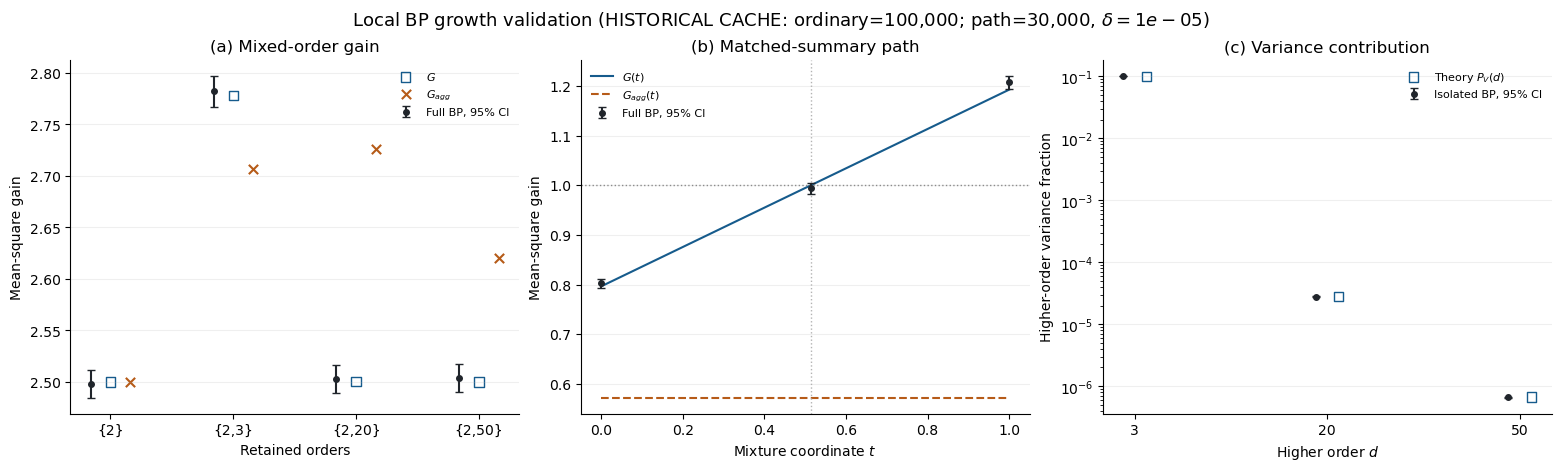

In [8]:
if report is not None:
    blue, orange, ink = '#165B8C', '#B65B18', '#20252B'
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), constrained_layout=True)

    # (a) Mixtures: complete BP measurements and the two theoretical predictions.
    selected = [by_name[name] for name in ('pair_only', 'mixture_2_3', 'mixture_2_20', 'mixture_2_50')]
    x = np.arange(len(selected))
    ax = axes[0]
    ax.errorbar(x-.16, [r['measurements'][-1]['mean'] for r in selected],
                yerr=[1.96*r['measurements'][-1]['standard_error'] for r in selected],
                fmt='o', color=ink, ms=4, capsize=3, label='Full BP, 95% CI')
    ax.scatter(x, [r['theory']['G'] for r in selected], marker='s',
               facecolors='none', edgecolors=blue, s=45, label=r'$G$')
    ax.scatter(x+.16, [r['theory']['G_aggregate'] for r in selected],
               marker='x', color=orange, s=45, label=r'$G_{agg}$')
    ax.set(xticks=x, xticklabels=['{2}', '{2,3}', '{2,20}', '{2,50}'],
           xlabel='Retained orders', ylabel='Mean-square gain', title='(a) Mixed-order gain')
    ax.legend(frameon=False, fontsize=8)

    # (b) Matched-summary path: recompute the theoretical curve and overlay three independent measurements.
    path = [by_name[name] for name in ('path_A', 'path_critical', 'path_B')]
    t = np.linspace(0, 1, 201)
    nu_a = np.array(path[0]['configuration']['nus'])
    nu_b = np.array(path[-1]['configuration']['nus'])
    path_theory = [predictions([2,4,8,16], (1-u)*nu_a+u*nu_b) for u in t]
    ax = axes[1]
    ax.plot(t, [p['G'] for p in path_theory], color=blue, label=r'$G(t)$')
    ax.plot(t, [p['G_aggregate'] for p in path_theory], '--', color=orange, label=r'$G_{agg}(t)$')
    ax.axhline(1, color='0.55', lw=1, ls=':')
    tc = path[1]['configuration']['path_t']
    ax.axvline(tc, color='0.7', lw=1, ls=':')
    ax.errorbar([r['configuration']['path_t'] for r in path],
                [r['measurements'][-1]['mean'] for r in path],
                yerr=[1.96*r['measurements'][-1]['standard_error'] for r in path],
                fmt='o', color=ink, ms=4, capsize=3, label='Full BP, 95% CI')
    ax.set(xlim=(-.05, 1.05), xlabel=r'Mixture coordinate $t$',
           ylabel='Mean-square gain', title='(b) Matched-summary path')
    ax.legend(frameon=False, fontsize=8, loc='upper left')

    # (c) Reconstruct the higher-order variance share from independent single-layer measurements.
    ax = axes[2]
    x = np.arange(3)
    ax.set_yscale('log')
    ax.errorbar(x-.06, [s['measured_P_V'] for s in shares],
                yerr=[1.96*s['delta_method_standard_error'] for s in shares],
                fmt='o', color=ink, ms=4, capsize=3, label='Isolated BP, 95% CI')
    ax.scatter(x+.06, [s['theoretical_P_V'] for s in shares], marker='s',
               facecolors='none', edgecolors=blue, s=45, label=r'Theory $P_V(d)$')
    ax.set(xticks=x, xticklabels=['3', '20', '50'], xlabel=r'Higher order $d$',
           ylabel='Higher-order variance fraction', title='(c) Variance contribution')
    ax.legend(frameon=False, fontsize=8)

    for ax in axes:
        ax.grid(axis='y', alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
    mode = ONE_GENERATION_SOURCE_LABEL if USE_CACHED_PLOT_DATA and not RUN_ONE_GENERATION else ('PILOT' if PILOT else 'FULL')
    fig.suptitle(fr'Local BP growth validation ({mode}, $\delta={AMPLITUDES[-1]:.0e}$)', fontsize=13)
    fig.savefig(OUT / 'bp_growth_validation.png', dpi=200, bbox_inches='tight')
    fig.savefig(OUT / 'bp_growth_validation.pdf', bbox_inches='tight')
    plt.show()

else:
    print("No new single-generation results; legacy table/plot skipped.")


The cached single-generation measurements use 30,000 path neighborhoods, with correct A/critical/B endpoints and seed rules. They reproduce that historical campaign, not a corrected 200,000-path rerun. The original 100k/200k rerun controls remain available explicitly. The two campaigns are never pooled. Multigeneration uses its separate original seed namespace.


## 8. Multigeneration normalized BP response

### 8.1 Message population and complete updates

The population has dimensions `(amplitude, sign, particle, label)`, rather than representing vertices of a finite hypergraph. Initialize $q_i^\pm=n\pm\delta\xi_i$ only at depth 0. At subsequent depths, draw $Z_d\sim\mathrm{Poisson}(\nu_d)$ for each order, sample complete child messages from the previous generation, and call the original `factor_kernel()` and `root_normalize()`.
**Replace the population only after the entire generation is complete. There is no Gaussian reinitialization, Jacobian update, damping, dropout, EM, or perturbation-variance reset.**

Symmetrize the finite population under label permutations: apply an independent uniform permutation to each sampled child-message pair, shared across signs and amplitudes. This represents the experiment's label-permutation-symmetric distribution and removes a persistent common label bias without changing paired-difference norms. It requires a uniform prior and permutation-invariant planted-partition affinity. Nonuniform priors or general affinities raise errors; the experiment does not estimate recovery conditional on true labels.

The observable is
$$\widehat{\mathcal R}_{\ell,\delta}=\frac1M\sum_i\left\|\frac{q_{i,+}^{(\ell)}-q_{i,-}^{(\ell)}}{2\delta}\right\|_2^2.$$
The finite-sample response mean is not subtracted. Diagnostics also record midpoint energy, the response-mean contribution, maximum deviation, probability validity, and normalization error.
The theoretical $\mathcal R_\ell\to G^\ell$ is a small-perturbation reference at fixed finite depth; assess finite-population bias separately by varying M.

In [9]:
from functools import lru_cache
import hashlib
import inspect
import marshal
from datetime import datetime, timezone
import warnings

import scipy
from scipy.special import stdtrit
from tqdm.auto import tqdm


def _positive_integer(value, name, minimum=1):
    if isinstance(value, (bool, np.bool_)) or int(value) != value or value < minimum:
        raise ValueError(f'{name} must be an integer >= {minimum}.')
    return int(value)


def _validate_symmetric_model(affinity, prior):
    """The permutation scheme is ONLY for a uniform prior and planted-partition C."""
    c = np.asarray(affinity, dtype=np.float64)
    p = np.asarray(prior, dtype=np.float64)
    if p.ndim != 1 or not 2 <= len(p) <= 8:
        raise ValueError('The symmetric population implementation supports 2 <= K <= 8.')
    k = len(p)
    if not np.isfinite(p).all() or not np.allclose(p, 1.0 / k, rtol=0, atol=1e-14):
        raise ValueError('Label-permutation sampling requires an exactly uniform prior.')
    if c.shape != (k, k) or not np.isfinite(c).all() or np.any(c <= 0):
        raise ValueError('Provide a finite, strictly positive K x K affinity matrix.')
    expected = np.full_like(c, c[0, 1])
    np.fill_diagonal(expected, c[0, 0])
    if not np.allclose(c, expected, rtol=1e-12, atol=1e-12):
        raise ValueError('This unconditional permutation experiment requires a planted-partition affinity.')
    return c, p


def _validate_orders_and_rates(orders, nus):
    d = np.asarray(orders, dtype=np.float64)
    nu = np.asarray(nus, dtype=np.float64)
    if d.ndim != 1 or len(d) == 0 or nu.shape != d.shape:
        raise ValueError('orders and nus must be nonempty, equally sized one-dimensional arrays.')
    if not np.isfinite(d).all() or np.any(d < 2) or np.any(d != np.floor(d)):
        raise ValueError('All orders must be finite integers >= 2.')
    if len(np.unique(d)) != len(d):
        raise ValueError('Duplicate orders are not allowed; combine their rates explicitly.')
    if not np.isfinite(nu).all() or np.any(nu < 0):
        raise ValueError('Poisson rates must be finite and nonnegative.')
    return d.astype(np.int64), nu


def _validate_amplitudes(amplitudes, prior):
    amp = np.asarray(amplitudes, dtype=np.float64)
    if amp.ndim != 1 or amp.size == 0 or not np.isfinite(amp).all():
        raise ValueError('amplitudes must be a finite, nonempty one-dimensional sequence.')
    if np.any(amp <= 0) or np.any(amp >= np.min(prior)):
        raise ValueError('Require 0 < amplitude < min(prior) to guarantee positive boundary messages.')
    return amp


@lru_cache(maxsize=7)
def _label_permutations(k):
    # For K=4 there are only 24 rows. No approximate row-wise shuffling is used.
    return np.array(list(itertools.permutations(range(k))), dtype=np.intp)


def initialize_population(population_size, amplitudes, rng, prior):
    """Return (A, 2, M, K) paired boundary probabilities; draw directions ONCE."""
    m = _positive_integer(population_size, 'population_size', minimum=2)
    p = np.asarray(prior, dtype=np.float64)
    if p.ndim != 1 or not np.isfinite(p).all() or np.any(p <= 0) or not np.isclose(p.sum(), 1):
        raise ValueError('prior must be a positive normalized vector.')
    amp = _validate_amplitudes(amplitudes, p)
    direction = rng.normal(size=(m, len(p)))
    direction -= direction.mean(axis=-1, keepdims=True)
    norm = np.linalg.norm(direction, axis=-1, keepdims=True)
    if np.any(norm == 0):
        raise FloatingPointError('A zero boundary direction was sampled; no silent replacement is made.')
    direction /= norm
    signs = np.array([1.0, -1.0])
    return (p[None, None, None, :]
            + amp[:, None, None, None] * signs[None, :, None, None]
            * direction[None, None, :, :])


def population_step(old_pool, orders, nus, rng, affinity, prior, batch_size=256):
    """One synchronous generation of the COMPLETE normalized BP update.

    Read only old_pool. Both signs and all amplitudes share factor counts,
    child indices, and each child's uniform label permutation. No Jacobian,
    attenuation, growth factor, fresh boundary noise, or rescaling is used.
    """
    c, p = _validate_symmetric_model(affinity, prior)
    dlist, rates = _validate_orders_and_rates(orders, nus)
    batch_size = _positive_integer(batch_size, 'batch_size')
    old = np.asarray(old_pool, dtype=np.float64)
    if old.ndim != 4 or old.shape[0] < 1 or old.shape[1] != 2 or old.shape[-1] != len(p) or old.shape[2] < 2:
        raise ValueError('old_pool must have shape (amplitudes, 2, M>=2, K).')
    if not np.isfinite(old).all() or np.any(old <= 0):
        raise FloatingPointError('Invalid input probabilities; probabilities are never clipped.')
    if not np.allclose(old.sum(axis=-1), 1.0, rtol=0, atol=3e-12):
        raise ValueError('Input messages are not normalized.')
    na, _, m, k = old.shape
    new = np.empty_like(old)
    permutations = _label_permutations(k)
    totals = np.zeros(len(dlist), dtype=np.int64)
    child_messages = 0
    zero_roots = 0
    max_degree = 0
    for offset in range(0, m, batch_size):
        n = min(batch_size, m - offset)
        logs = np.zeros((na, 2, n, k), dtype=np.float64)
        root_degree = np.zeros(n, dtype=np.int64)
        for layer, (d, nu) in enumerate(zip(dlist, rates)):
            d = int(d)
            z = rng.poisson(nu, size=n)
            root_degree += z
            factor_roots = np.repeat(np.arange(n), z)
            nf = len(factor_roots)
            totals[layer] += nf
            child_messages += nf * (d - 1)
            if nf == 0:
                continue
            indices = rng.integers(0, m, size=(nf, d - 1))
            perm = permutations[rng.integers(0, len(permutations), size=(nf, d - 1))]
            for ai in range(na):
                for si in range(2):
                    incoming = np.take_along_axis(old[ai, si][indices], perm, axis=-1)
                    factors = factor_kernel(incoming, c)
                    if not np.isfinite(factors).all() or np.any(factors <= 0):
                        raise FloatingPointError('Nonpositive or nonfinite complete factor message.')
                    factors /= factors.sum(axis=-1, keepdims=True)
                    log_factors = np.log(factors)
                    for label in range(k):
                        logs[ai, si, :, label] += np.bincount(
                            factor_roots, weights=log_factors[:, label], minlength=n)
        q = root_normalize(logs, p)
        if not np.isfinite(q).all() or np.any(q <= 0):
            raise FloatingPointError('Root normalization underflow/invalid probability; reduce depth or amplitude.')
        new[:, :, offset:offset + n, :] = q
        zero_roots += int(np.count_nonzero(root_degree == 0))
        max_degree = max(max_degree, int(root_degree.max()))
    diagnostics = dict(incidence_totals=totals, child_messages=int(child_messages),
                       zero_factor_roots=zero_roots, max_total_incidence=max_degree)
    return new, diagnostics


def population_observables(pool, amplitudes, prior):
    """Measure raw paired responses, WITHOUT centering or amplitude resetting."""
    amp = np.asarray(amplitudes, dtype=np.float64)
    p = np.asarray(prior, dtype=np.float64)
    response = (pool[:, 0] - pool[:, 1]) / (2 * amp[:, None, None])
    squared = np.sum(response**2, axis=-1)
    mean_square = squared.mean(axis=-1)
    response_mean = response.mean(axis=1)
    midpoint = 0.5 * (pool[:, 0] + pool[:, 1]) - p
    midpoint_energy = np.sum(midpoint**2, axis=-1).mean(axis=-1)
    pair_energy = amp**2 * mean_square
    midpoint_ratio = np.divide(midpoint_energy, pair_energy,
                               out=np.where(midpoint_energy > 0, np.inf, 0.0), where=pair_energy > 0)
    bias_fraction = np.divide(np.sum(response_mean**2, axis=-1), mean_square,
                              out=np.zeros_like(mean_square), where=mean_square > 0)
    return dict(R=mean_square, squared_response=squared,
                response_component_mean=response_mean,
                response_mean_bias_fraction=bias_fraction,
                midpoint_energy=midpoint_energy, midpoint_to_pair_energy=midpoint_ratio,
                mean_message=pool.mean(axis=2),
                max_abs_deviation=np.max(np.abs(pool - p), axis=(1, 2, 3)),
                min_probability=np.min(pool, axis=(1, 2, 3)),
                normalization_error=np.max(np.abs(pool.sum(axis=-1) - 1), axis=(1, 2)))


def simulate_multigeneration(orders, nus, *, population_size, depth, amplitudes,
                            seed, batch_size=256, affinity=None, prior=None,
                            save_root_responses=True, progress_callback=None):
    """Paired finite-depth population dynamics; theoretical predictions are external.

    Each new generation is sampled from the permutation-symmetrized previous
    empirical message law. M is a message-population size, NOT a graph size.
    Independent full calls, not particles or depths, are the statistical replicates.
    """
    depth = _positive_integer(depth, 'depth', minimum=0)
    m = _positive_integer(population_size, 'population_size', minimum=2)
    p0 = np.full(K, 1 / K) if prior is None else prior
    c0 = affinity_matrix() if affinity is None else affinity
    c, p = _validate_symmetric_model(c0, p0)
    dlist, rates = _validate_orders_and_rates(orders, nus)
    amp = _validate_amplitudes(amplitudes, p)
    rng = np.random.default_rng(seed)
    pool = initialize_population(m, amp, rng, p)
    start = time.perf_counter()
    history = {}
    raw_responses = []
    incidence = []
    children = []
    zero_roots = []
    max_degrees = []
    for ell in range(depth + 1):
        if ell:
            new_pool, counts = population_step(pool, dlist, rates, rng, c, p, batch_size)
            pool = new_pool  # Only swap AFTER the ENTIRE generation has been completed.
            incidence.append(counts['incidence_totals'])
            children.append(counts['child_messages'])
            zero_roots.append(counts['zero_factor_roots'])
            max_degrees.append(counts['max_total_incidence'])
        obs = population_observables(pool, amp, p)
        for key, value in obs.items():
            if key == 'squared_response':
                if save_root_responses:
                    raw_responses.append(value)
            else:
                history.setdefault(key, []).append(value)
        if ell and progress_callback is not None:
            progress_callback(ell, obs)
    result = {key: np.stack(value, axis=0) for key, value in history.items()}
    result.update(depths=np.arange(depth + 1), amplitudes=amp,
                  squared_response=(np.stack(raw_responses) if save_root_responses
                                    else np.empty((0, len(amp), 0))),
                  last_population=pool,
                  incidence_totals=np.asarray(incidence, dtype=np.int64).reshape(depth, len(dlist)),
                  child_messages=np.asarray(children, dtype=np.int64),
                  zero_factor_roots=np.asarray(zero_roots, dtype=np.int64),
                  max_total_incidence=np.asarray(max_degrees, dtype=np.int64),
                  elapsed_seconds=float(time.perf_counter() - start))
    return result


def summarize_multigeneration(R_runs, *, amplitudes, bootstrap_seed, bootstrap_samples=2000):
    """Student-t pointwise CIs across runs; ratio CIs resample complete trajectories."""
    values = np.asarray(R_runs, dtype=np.float64)
    amp = np.asarray(amplitudes, dtype=np.float64)
    if values.ndim != 3 or values.shape[0] < 2 or values.shape[2] != len(amp):
        raise ValueError('R_runs must have shape (independent runs >=2, depths, amplitudes).')
    if not np.isfinite(values).all() or np.any(values < 0):
        raise ValueError('Responses must be finite and nonnegative.')
    nboot = _positive_integer(bootstrap_samples, 'bootstrap_samples', minimum=100)
    nr = values.shape[0]
    mean = values.mean(axis=0)
    sd = values.std(axis=0, ddof=1)
    se = sd / np.sqrt(nr)
    critical = float(stdtrit(nr - 1, 0.975))
    halfwidth = critical * se
    ratio = np.divide(mean[1:], mean[:-1], out=np.full_like(mean[1:], np.nan), where=mean[:-1] > 0)
    rng = np.random.default_rng(bootstrap_seed)
    indices = rng.integers(0, nr, size=(nboot, nr))
    boot_mean = values[indices].mean(axis=1)  # All depths and amplitudes stay together.
    boot_ratio = np.divide(boot_mean[:, 1:], boot_mean[:, :-1],
                           out=np.full_like(boot_mean[:, 1:], np.nan), where=boot_mean[:, :-1] > 0)
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='All-NaN slice encountered')
        ratio_low, ratio_high = np.nanquantile(boot_ratio, [0.025, 0.975], axis=0)
    ref = int(np.argmin(amp))
    differences = values - values[:, :, ref:ref + 1]
    diff_mean = differences.mean(axis=0)
    diff_se = differences.std(axis=0, ddof=1) / np.sqrt(nr)
    return dict(mean_R=mean, sd_R=sd, se_R=se, halfwidth95_R=halfwidth,
                ci95_low_R=mean - halfwidth, ci95_high_R=mean + halfwidth,
                effective_gain=ratio, effective_gain_ci95_low=ratio_low,
                effective_gain_ci95_high=ratio_high,
                amplitude_difference_mean=diff_mean, amplitude_difference_se=diff_se,
                amplitude_difference_halfwidth95=critical * diff_se,
                reference_amplitude=float(amp[ref]), t_critical=critical,
                independent_runs=nr, bootstrap_samples=nboot,
                interval_scope='pointwise approximate intervals, not simultaneous bands')


### 8.2 Implementation checks

Check the original factor kernel, endpoints, uniform fixed point, empty neighborhoods, exchange of signs, permutation averages, preservation of the old population, explicit enumeration of small factors, and synchronous two-generation replay.
These checks do not accept samples or continue sampling according to whether random measurements contain the theoretical value.

In [10]:
def multigeneration_checks():
    """Small deterministic checks; no statistical sample is accepted/rejected against G."""
    checks = {}
    p = np.full(K, 1 / K)
    c = affinity_matrix()
    _validate_symmetric_model(c, p)
    by_config = {row['name']: row for row in cases(False)}
    assert by_config['path_A']['path_t'] == 0.0
    assert by_config['path_B']['path_t'] == 1.0
    assert len(by_config) == 10
    endpoints = [predictions(by_config[name]['orders'], by_config[name]['nus'])
                 for name in ('path_A', 'path_B')]
    for key in ('mean_incidence', 'F', 'G_aggregate'):
        assert abs(endpoints[0][key] - endpoints[1][key]) < 1e-11
    assert endpoints[0]['G'] < 1 < endpoints[1]['G']
    checks['endpoint_configuration'] = dict(A_t=0.0, B_t=1.0,
        A_G=endpoints[0]['G'], B_G=endpoints[1]['G'], aggregate=endpoints[0]['G_aggregate'])
    pool = initialize_population(37, (1e-3, 1e-4, 1e-5), np.random.default_rng(740019), p)
    obs = population_observables(pool, (1e-3, 1e-4, 1e-5), p)
    assert np.max(np.abs(obs['R'] - 1)) < 1e-10
    checks['initial_unit_response_max_error'] = float(np.max(np.abs(obs['R'] - 1)))
    uniform = np.full_like(pool, 1 / K)
    unchanged, _ = population_step(uniform, [2, 3, 4], [2., 1., 0.5], np.random.default_rng(51), c, p, 11)
    assert np.max(np.abs(unchanged - uniform)) < 1e-13
    checks['uniform_fixed_point_max_error'] = float(np.max(np.abs(unchanged - uniform)))
    before = pool.copy()
    first, _ = population_step(pool, [2, 3], [2., 1.], np.random.default_rng(52), c, p, 11)
    assert np.array_equal(pool, before)
    swapped, _ = population_step(pool[:, ::-1], [2, 3], [2., 1.], np.random.default_rng(52), c, p, 11)
    assert np.max(np.abs(first - swapped[:, ::-1])) < 1e-13
    checks['sign_swap_max_error'] = float(np.max(np.abs(first - swapped[:, ::-1])))
    checks['old_population_unmodified'] = True
    permutations = _label_permutations(K)
    averaged = pool[0, 0, 0][permutations].mean(axis=0)
    assert np.max(np.abs(averaged - p)) < 1e-14
    checks['virtual_permutation_mean_max_error'] = float(np.max(np.abs(averaged - p)))
    zero, _ = population_step(pool, [2, 3], [0., 0.], np.random.default_rng(53), c, p, 11)
    assert np.max(np.abs(zero - p)) < 1e-14
    checks['empty_neighborhood_prior'] = True
    # Replay a tiny full mixed-order population step with explicit label enumeration.
    m, seed = 5, 740020
    tiny = initialize_population(m, (0.01,), np.random.default_rng(54), p)
    fast, _ = population_step(tiny, [2, 3], [1.7, 0.9], np.random.default_rng(seed), c, p, m)
    rng = np.random.default_rng(seed)
    brute = np.broadcast_to(p, tiny.shape).copy()
    for d, nu in ((2, 1.7), (3, 0.9)):
        z = rng.poisson(nu, size=m)
        roots = np.repeat(np.arange(m), z)
        nf = len(roots)
        if not nf:
            continue
        idx = rng.integers(0, m, size=(nf, d - 1))
        perms = permutations[rng.integers(0, len(permutations), size=(nf, d - 1))]
        for f, root in enumerate(roots):
            for sign in range(2):
                incoming = np.array([tiny[0, sign, idx[f, j], perms[f, j]] for j in range(d - 1)])
                brute[0, sign, root] *= enumerate_factor(incoming, c)
    brute /= brute.sum(axis=-1, keepdims=True)
    error = float(np.max(np.abs(fast - brute)))
    assert error < 1e-12
    checks['explicit_mixed_population_step_max_error'] = error
    # Verify two synchronous generations against an explicit two-step replay.
    seed = 740021
    rng = np.random.default_rng(seed)
    manual = initialize_population(31, (1e-4,), rng, p)
    for _ in range(2):
        manual, _ = population_step(manual, [2, 3], [1.2, 0.8], rng, c, p, 8)
    actual = simulate_multigeneration([2, 3], [1.2, 0.8], population_size=31,
        depth=2, amplitudes=(1e-4,), seed=seed, batch_size=8, affinity=c, prior=p)
    assert np.array_equal(manual, actual['last_population'])
    checks['two_generation_replay_exact'] = True
    return checks


In [11]:
MG_CHECK_RESULTS = None
if MG_RUN_CHECKS:
    MG_CHECK_RESULTS = dict(original_kernel=deterministic_checks(),
                            multigeneration=multigeneration_checks())
    print(json.dumps(MG_CHECK_RESULTS, indent=2, ensure_ascii=False))
else:
    print("Implementation checks skipped by MG_RUN_CHECKS=False.")


{
  "original_kernel": {
    "explicit_factor_enumeration_cases": 12,
    "max_factor_relative_error": 9.765038985015176e-16,
    "explicit_full_root_error": 1.6653345369377348e-16,
    "single_branch_finite_differences": [
      {
        "d": 2,
        "max_absolute_error": 3.594458064526407e-12
      },
      {
        "d": 3,
        "max_absolute_error": 1.1148096334956392e-12
      },
      {
        "d": 4,
        "max_absolute_error": 3.185007813044649e-12
      },
      {
        "d": 20,
        "max_absolute_error": 1.8449429267305972e-12
      },
      {
        "d": 50,
        "max_absolute_error": 6.318871207527943e-13
      }
    ]
  },
  "multigeneration": {
    "endpoint_configuration": {
      "A_t": 0.0,
      "B_t": 1.0,
      "A_G": 0.7964838546582858,
      "B_G": 1.1927375112877592,
      "aggregate": 0.5722398599724331
    },
    "initial_unit_response_max_error": 2.9820590441431705e-13,
    "uniform_fixed_point_max_error": 0.0,
    "sign_swap_max_error": 0.0

### 8.3 Independent runs, saving, and execution

Each `(mode, M, case, repeat)` uses seed entropy `[mode_id, M, case_id, repeat, MG_SEED]`, initialized through NumPy `default_rng`. Amplitudes are paired **within a run**; different modes are analyzed separately. Save one NPZ per independent run, and write configuration and all seeds to the manifest before the first measurement.
On interruption, completed runs are retained and the manifest is marked interrupted/failed. Reruns create new directories rather than merging partial and complete results automatically.

Means and pointwise approximate 95% Student-t intervals are computed across independent runs. The effective gain is a **ratio of means**; bootstrap intervals resample complete run trajectories. With few runs, especially the pilot's three, bootstrap intervals are exploratory and exclude systematic finite-M bias.

In [12]:
def multigeneration_settings(mode, *, custom_population=20_000, custom_depth=12,
                             custom_repeats=10, custom_amplitudes=(1e-4,)):
    """Separate pilot, main, and numerical-control protocols; never silently mix them."""
    profiles = {
        'pilot': dict(populations=[2_000], depth=4, repeats=3, amplitudes=[1e-4], mode_id=0),
        'main': dict(populations=[20_000], depth=12, repeats=10, amplitudes=[1e-4], mode_id=1),
        'amplitude_check': dict(populations=[20_000], depth=12, repeats=5,
                                amplitudes=[1e-3, 1e-4, 1e-5], mode_id=2),
        'population_check': dict(populations=[5_000, 20_000, 80_000], depth=12,
                                 repeats=5, amplitudes=[1e-4], mode_id=3),
        'custom': dict(populations=[custom_population], depth=custom_depth,
                       repeats=custom_repeats, amplitudes=list(custom_amplitudes), mode_id=4),
    }
    if mode not in profiles:
        raise ValueError(f'Unknown MG_MODE={mode!r}; choose from {tuple(profiles)}.')
    setting = profiles[mode]
    setting['populations'] = [_positive_integer(m, 'population', 2) for m in setting['populations']]
    setting['depth'] = _positive_integer(setting['depth'], 'depth', 1)
    setting['repeats'] = _positive_integer(setting['repeats'], 'repeats', 2)
    _validate_amplitudes(setting['amplitudes'], np.full(K, 1 / K))
    return setting


def _json_ready(value):
    if isinstance(value, dict):
        return {str(key): _json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_json_ready(item) for item in value]
    if isinstance(value, np.ndarray):
        return _json_ready(value.tolist())
    if isinstance(value, np.generic):
        return _json_ready(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None  # Undefined ratios are explicitly null in JSON, NaN in NPZ.
    if isinstance(value, Path):
        return str(value)
    return value


def _write_json_atomic(path, data):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(_json_ready(data), ensure_ascii=False, indent=2,
                                    allow_nan=False) + '\n', encoding='utf-8')
    temporary.replace(path)


def _write_csv(path, rows):
    if not rows:
        return
    with Path(path).open('w', newline='', encoding='utf-8-sig') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def _runtime_fingerprint():
    names = ['factor_kernel', 'root_normalize', 'affinity_matrix', 'predictions', 'cases',
             '_positive_integer', '_label_permutations', '_validate_symmetric_model',
             '_validate_orders_and_rates', '_validate_amplitudes',
             'initialize_population', 'population_step', 'population_observables',
             'simulate_multigeneration', 'summarize_multigeneration', 'multigeneration_settings']
    digest = hashlib.sha256()
    source_parts = []
    for name in names:
        fn = inspect.unwrap(globals()[name])
        digest.update(name.encode('utf-8'))
        digest.update(marshal.dumps(fn.__code__))
        try:
            source_parts.append(inspect.getsource(fn))
        except (OSError, TypeError):
            pass
    return digest.hexdigest(), '\n\n'.join(source_parts)


def run_multigeneration_experiment(*, mode, output_root, base_seed, case_names=('path_A', 'path_B'),
                                  batch_size=256, bootstrap_samples=2000,
                                  save_root_responses=True, save_last_population=True,
                                  custom_population=20_000, custom_depth=12,
                                  custom_repeats=10, custom_amplitudes=(1e-4,),
                                  validation_results=None):
    """Run all requested independent replicates; save each one before proceeding.

    A new timestamped directory prevents overwriting historical measurements.
    A failed/interrupted campaign is marked as such; its completed runs remain.
    Numerical-control modes use distinct random streams from pilot and main.
    """
    setting = multigeneration_settings(mode, custom_population=custom_population,
                                      custom_depth=custom_depth, custom_repeats=custom_repeats,
                                      custom_amplitudes=custom_amplitudes)
    all_cases = {row['name']: row for row in cases(False)}
    allowed = {'path_A': 0, 'path_B': 1, 'path_critical': 2}
    if not case_names or len(set(case_names)) != len(case_names) or any(n not in allowed for n in case_names):
        raise ValueError('Choose distinct case names from path_A, path_B, path_critical.')
    if all_cases['path_A']['path_t'] != 0 or all_cases['path_B']['path_t'] != 1:
        raise ValueError('Incorrect endpoint labels: require path_A at t=0 and path_B at t=1.')
    # Freeze the model passed to every numerical replicate in this campaign.
    affinity, prior = _validate_symmetric_model(affinity_matrix(), np.full(K, 1 / K))
    mode_id = setting['mode_id']
    base_seed = _positive_integer(base_seed, 'base_seed', 0)
    batch_size = _positive_integer(batch_size, 'batch_size')
    timestamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    directory = Path(output_root) / f'{mode}_{timestamp}'
    directory.mkdir(parents=True, exist_ok=False)
    fingerprint, source_text = _runtime_fingerprint()
    if source_text:
        (directory / 'executed_function_sources.txt').write_text(source_text, encoding='utf-8')
    plan = []
    for name in case_names:
        case = all_cases[name]
        for m in setting['populations']:
            for repeat in range(setting['repeats']):
                entropy = [mode_id, m, allowed[name], repeat, base_seed]
                plan.append(dict(case=name, population_size=m, repeat=repeat,
                                 seed_entropy=entropy, orders=case['orders'], nus=case['nus'],
                                 path_t=case['path_t']))
    manifest = dict(
        experiment='Finite-depth paired complete-BP population response', status='running',
        created_utc=timestamp, mode=mode, settings=setting, case_names=list(case_names),
        K=K, c0=C0, signal=SIGNAL, affinity=affinity, prior=prior,
        batch_size=batch_size, base_seed=base_seed, bit_generator='PCG64',
        permutation_protocol='Independent uniform label permutation per sampled child, shared across signs/amplitudes',
        synchronous_generations=True, boundary_reinitialized_each_generation=False,
        response_renormalized_each_generation=False, theory_in_measurement_kernel=False,
        statistical_unit='Independent complete population run; particles and depths are not independent replicates',
        scope='Label-independent centered boundary noise; not finite-graph recovery or information-theoretic threshold',
        save_root_responses=bool(save_root_responses), save_last_population=bool(save_last_population),
        bootstrap_samples=int(bootstrap_samples), python=sys.version,
        numpy=np.__version__, scipy=scipy.__version__, platform=platform.platform(),
        executed_code_objects_sha256=fingerprint,
        fingerprint_note='Hash of actually loaded Python code objects; includes interpreter/session-specific metadata',
        validation_results=validation_results, planned_runs=plan, completed_runs=[],
    )
    _write_json_atomic(directory / 'manifest.json', manifest)  # Before the first measurement.
    print(f'Mode={mode}; cases={tuple(case_names)}; M={setting["populations"]}; '
          f'depth={setting["depth"]}; independent runs={setting["repeats"]}; delta={setting["amplitudes"]}')
    print(f'Output: {directory.resolve()}')
    if mode == 'pilot':
        print('PILOT: implementation/scale check only; not the main experimental sample.')
    groups = {}
    total_generations = len(plan) * setting['depth']
    start = time.perf_counter()
    try:
        with tqdm(total=total_generations, desc='Multi-generation BP', unit='gen', dynamic_ncols=True) as progress:
            for item in plan:
                name, m, repeat = item['case'], item['population_size'], item['repeat']
                progress.set_postfix_str(f'{name}, M={m}, run {repeat + 1}/{setting["repeats"]}')
                def callback(ell, obs):
                    progress.update(1)
                run = simulate_multigeneration(
                    item['orders'], item['nus'], population_size=m, depth=setting['depth'],
                    amplitudes=setting['amplitudes'], seed=item['seed_entropy'], batch_size=batch_size,
                    affinity=affinity, prior=prior, save_root_responses=save_root_responses,
                    progress_callback=callback)
                raw_name = f'{name}_M{m}_run{repeat:02d}.npz'
                payload = {key: value for key, value in run.items()
                           if key != 'last_population' or save_last_population}
                payload.update(seed_entropy=np.asarray(item['seed_entropy'], dtype=np.uint64),
                               orders=np.asarray(item['orders']), nus=np.asarray(item['nus']),
                               affinity=affinity, prior=prior, mode=np.array(mode),
                               case=np.array(name), population_size=np.array(m))
                np.savez_compressed(directory / raw_name, **payload)
                record = dict(**item, file=raw_name,
                              sha256=hashlib.sha256((directory / raw_name).read_bytes()).hexdigest(),
                              elapsed_seconds=run['elapsed_seconds'], final_R=run['R'][-1],
                              max_normalization_error=float(run['normalization_error'].max()),
                              max_midpoint_to_pair_energy=float(run['midpoint_to_pair_energy'].max()))
                manifest['completed_runs'].append(record)
                _write_json_atomic(directory / 'manifest.json', manifest)
                key = (name, m)
                groups.setdefault(key, dict(R=[], diagnostics=[], seeds=[]))
                groups[key]['R'].append(run['R'])
                groups[key]['seeds'].append(item['seed_entropy'])
                groups[key]['diagnostics'].append({k: run[k] for k in (
                    'midpoint_to_pair_energy', 'response_mean_bias_fraction', 'max_abs_deviation',
                    'min_probability', 'normalization_error', 'incidence_totals')})
                progress.write(f'{name} M={m} run={repeat + 1}: '
                               f'R(depth={setting["depth"]})={np.array2string(run["R"][-1], precision=6)}; '
                               f'{run["elapsed_seconds"]:.1f} s')
                del run, payload
        results = []
        csv_rows = []
        diag_rows = []
        for (name, m), data in groups.items():
            R_runs = np.stack(data['R'])
            bootstrap_seed = [9001, mode_id, m, allowed[name], base_seed]
            summary = summarize_multigeneration(R_runs, amplitudes=setting['amplitudes'],
                                               bootstrap_seed=bootstrap_seed, bootstrap_samples=bootstrap_samples)
            config = all_cases[name]
            theory = predictions(config['orders'], config['nus'])  # Comparison ONLY, after measurements.
            entry = dict(case=name, population_size=m, path_t=config['path_t'],
                         orders=config['orders'], nus=config['nus'], R_runs=R_runs,
                         seed_entropy=np.asarray(data['seeds'], dtype=np.uint64),
                         bootstrap_seed=bootstrap_seed, summary=summary, theory=theory)
            results.append(entry)
            for ell in range(setting['depth'] + 1):
                for ai, amp in enumerate(setting['amplitudes']):
                    csv_rows.append(dict(
                        case=name, population_size=m, depth=ell, amplitude=amp,
                        independent_runs=setting['repeats'], mean_R=float(summary['mean_R'][ell, ai]),
                        sd_R=float(summary['sd_R'][ell, ai]), se_R=float(summary['se_R'][ell, ai]),
                        ci95_low_R=float(summary['ci95_low_R'][ell, ai]),
                        ci95_high_R=float(summary['ci95_high_R'][ell, ai]),
                        G_theory=theory['G'], G_power_theory=theory['G']**ell,
                        G_aggregate_theory=theory['G_aggregate'],
                        paired_difference_from_smallest_amplitude=float(summary['amplitude_difference_mean'][ell, ai]),
                        paired_difference_halfwidth95=float(summary['amplitude_difference_halfwidth95'][ell, ai]),
                        effective_gain_from_previous=(float(summary['effective_gain'][ell - 1, ai]) if ell else ''),
                        effective_gain_ci95_low=(float(summary['effective_gain_ci95_low'][ell - 1, ai]) if ell else ''),
                        effective_gain_ci95_high=(float(summary['effective_gain_ci95_high'][ell - 1, ai]) if ell else '')))
            for repeat, diag in enumerate(data['diagnostics']):
                for ell in range(setting['depth'] + 1):
                    for ai, amp in enumerate(setting['amplitudes']):
                        diag_rows.append(dict(case=name, population_size=m, repeat=repeat, depth=ell, amplitude=amp,
                            **{key: float(diag[key][ell, ai]) for key in (
                                'midpoint_to_pair_energy', 'response_mean_bias_fraction',
                                'max_abs_deviation', 'min_probability', 'normalization_error')}))
        _write_csv(directory / 'measurements.csv', csv_rows)
        _write_csv(directory / 'diagnostics.csv', diag_rows)
        # Compact aggregate: (group, independent run, depth, amplitude).
        np.savez_compressed(directory / 'multigeneration_runs.npz',
                            R_runs=np.stack([entry['R_runs'] for entry in results]),
                            case_names=np.array([entry['case'] for entry in results]),
                            population_sizes=np.array([entry['population_size'] for entry in results]),
                            seeds=np.stack([entry['seed_entropy'] for entry in results]),
                            depths=np.arange(setting['depth'] + 1), amplitudes=np.array(setting['amplitudes']),
                            mean_R=np.stack([e['summary']['mean_R'] for e in results]),
                            ci95_low_R=np.stack([e['summary']['ci95_low_R'] for e in results]),
                            ci95_high_R=np.stack([e['summary']['ci95_high_R'] for e in results]))
        final = dict(directory=str(directory.resolve()), mode=mode, settings=setting, results=results,
                     elapsed_seconds=float(time.perf_counter() - start))
        _write_json_atomic(directory / 'summary.json', final)
        manifest.update(status='complete', elapsed_seconds=final['elapsed_seconds'])
        _write_json_atomic(directory / 'manifest.json', manifest)
    except BaseException as exc:
        manifest.update(status='interrupted' if isinstance(exc, KeyboardInterrupt) else 'failed',
                        error=f'{type(exc).__name__}: {exc}', elapsed_seconds=float(time.perf_counter() - start))
        _write_json_atomic(directory / 'manifest.json', manifest)
        raise
    print(f'Completed {len(plan)} independent runs. Results: {directory.resolve()}')
    return final


In [13]:
def load_multigeneration_plot_data():
    """Recompute summaries from the original independent-run trajectories."""
    manifest = json.loads(cached_plot_file('multigeneration_main/manifest.json').read_text(encoding='utf-8'))
    result = json.loads(cached_plot_file('multigeneration_main/summary.json').read_text(encoding='utf-8'))
    assert manifest['status'] == 'complete' and len(manifest['completed_runs']) == 20
    assert result['mode'] == MG_MODE == 'main'
    assert tuple(manifest['case_names']) == tuple(MG_CASE_NAMES)
    assert manifest['base_seed'] == MG_SEED and manifest['batch_size'] == MG_BATCH_SIZE
    assert manifest['bootstrap_samples'] == MG_BOOTSTRAP_SAMPLES
    assert (manifest['K'], manifest['c0'], manifest['signal']) == (K, C0, SIGNAL)
    expected_setting = multigeneration_settings(MG_MODE)
    assert result['settings'] == expected_setting
    expected_cases = {row['name']: row for row in cases(False)}
    with np.load(cached_plot_file('multigeneration_main/multigeneration_runs.npz'), allow_pickle=False) as packed:
        assert packed['R_runs'].shape == (2, 10, 13, 1)
        np.testing.assert_array_equal(packed['depths'], np.arange(13))
        np.testing.assert_array_equal(packed['amplitudes'], expected_setting['amplitudes'])
        for index, entry in enumerate(result['results']):
            name = entry['case']
            assert str(packed['case_names'][index]) == name
            assert entry['population_size'] == int(packed['population_sizes'][index]) == 20000
            assert entry['orders'] == expected_cases[name]['orders']
            np.testing.assert_allclose(entry['nus'], expected_cases[name]['nus'], rtol=1e-14)
            entry['R_runs'] = np.asarray(entry['R_runs'], dtype=float)
            np.testing.assert_array_equal(entry['R_runs'], packed['R_runs'][index])
            np.testing.assert_array_equal(entry['seed_entropy'], packed['seeds'][index])
            summary = summarize_multigeneration(
                entry['R_runs'], amplitudes=expected_setting['amplitudes'],
                bootstrap_seed=entry['bootstrap_seed'], bootstrap_samples=MG_BOOTSTRAP_SAMPLES)
            for key in ('mean_R', 'halfwidth95_R', 'effective_gain', 'effective_gain_ci95_low', 'effective_gain_ci95_high'):
                np.testing.assert_allclose(summary[key], entry['summary'][key], rtol=1e-11, atol=1e-14)
            entry['summary'] = summary
            theory = predictions(entry['orders'], entry['nus'])
            np.testing.assert_allclose(entry['theory']['G'], theory['G'], rtol=1e-13)
            entry['theory'] = theory
    out = PLOT_OUTPUT_ROOT / 'multigeneration_cached_main'
    out.mkdir(parents=True, exist_ok=True)
    result['directory'] = str(out.resolve())
    print('Loaded original main cache: M=20,000; depth=12; 10 independent runs/case; no new simulation.')
    return result


mg_result = None
if RUN_MULTIGENERATION:
    mg_result = run_multigeneration_experiment(
        mode=MG_MODE, output_root=MG_OUTPUT_ROOT, base_seed=MG_SEED,
        case_names=MG_CASE_NAMES, batch_size=MG_BATCH_SIZE,
        bootstrap_samples=MG_BOOTSTRAP_SAMPLES,
        save_root_responses=MG_SAVE_ROOT_RESPONSES,
        save_last_population=MG_SAVE_LAST_POPULATION,
        custom_population=MG_CUSTOM_POPULATION, custom_depth=MG_CUSTOM_DEPTH,
        custom_repeats=MG_CUSTOM_REPEATS, custom_amplitudes=MG_CUSTOM_AMPLITUDES,
        validation_results=MG_CHECK_RESULTS,
    )
elif USE_CACHED_PLOT_DATA:
    mg_result = load_multigeneration_plot_data()
else:
    print("Multi-generation measurements and plots disabled.")


Loaded original main cache: M=20,000; depth=12; 10 independent runs/case; no new simulation.


### 8.4 Multigeneration plots and statistics

Export separate response (logarithmic y-axis), effective-gain, and measurement/theory-ratio plots as PNG and PDF. Measured points come from actual generation-by-generation propagation; $G^\ell$ is a reference with no fitted parameters. Seeds, depth windows, and amplitudes are not selected for agreement with theory.

In [14]:
def show_multigeneration_results(result):
    if result is None:
        print('Multi-generation experiment skipped; there are no new measurements to plot.')
        return
    settings = result['settings']
    entries = result['results']
    out = Path(result['directory'])
    depths = np.arange(settings['depth'] + 1)
    amplitudes = settings['amplitudes']
    marker_choices = ('o', 's', '^', 'D', 'v', 'P', 'X', '<', '>')
    mode_label = result['mode'].upper()
    print('\nFinal-depth responses: mean ± pointwise approximate 95% half-width (independent runs)')
    print(f'{"case":<15} {"M":>8} {"delta":>10} {"mean R":>13} {"half-width":>13} {"G^L (theory)":>15}')
    for entry in entries:
        for ai, amp in enumerate(amplitudes):
            s = entry['summary']
            print(f'{entry["case"]:<15} {entry["population_size"]:8d} {amp:10.1e} '
                  f'{s["mean_R"][-1, ai]:13.6g} {s["halfwidth95_R"][-1, ai]:13.6g} '
                  f'{entry["theory"]["G"]**settings["depth"]:15.6g}')
    def series():
        index = 0
        for entry in entries:
            for ai, amp in enumerate(amplitudes):
                label = f'{entry["case"]}, M={entry["population_size"]:,}, delta={amp:.0e}'
                yield entry, ai, amp, label, marker_choices[index % len(marker_choices)]
                index += 1
    # Every figure is separate. Actual responses and analytical curves are separately labeled.
    fig, ax = plt.subplots(figsize=(8.4, 5.3), constrained_layout=True)
    for entry, ai, amp, label, marker in series():
        s = entry['summary']
        ax.errorbar(depths, s['mean_R'][:, ai], yerr=s['halfwidth95_R'][:, ai],
                    marker=marker, markersize=3.5, linewidth=1.1, capsize=2, label=label)
    shown = set()
    for entry in entries:
        if entry['case'] not in shown:
            ax.plot(depths, entry['theory']['G']**depths, '--', linewidth=1.5,
                    label=f'{entry["case"]}: theoretical G^ell')
            shown.add(entry['case'])
    ax.set(yscale='log', xlabel='Generation (factor crossings)',
           ylabel=r'$\overline{\mathcal{R}}_{\ell,\delta}$',
           title=f'Complete normalized BP: multi-generation response [{mode_label}]')
    ax.set_xticks(depths)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, frameon=False)
    fig.savefig(out / 'multigeneration_response.png', dpi=200)
    fig.savefig(out / 'multigeneration_response.pdf')
    plt.show()

    fig, ax = plt.subplots(figsize=(8.4, 5.3), constrained_layout=True)
    for entry, ai, amp, label, marker in series():
        s = entry['summary']
        ax.plot(depths[1:], s['effective_gain'][:, ai], marker=marker, markersize=3.5,
                linewidth=1.1, label=label)
        ax.fill_between(depths[1:], s['effective_gain_ci95_low'][:, ai],
                        s['effective_gain_ci95_high'][:, ai], alpha=0.15)
    shown = set()
    for entry in entries:
        if entry['case'] not in shown:
            ax.axhline(entry['theory']['G'], linestyle='--', linewidth=1.3,
                       label=f'{entry["case"]}: theoretical G={entry["theory"]["G"]:.6f}')
            shown.add(entry['case'])
    ax.axhline(1, linestyle=':', linewidth=1)
    ax.set(xlabel='Output generation', ylabel=r'$\overline{\mathcal{R}}_{\ell}/\overline{\mathcal{R}}_{\ell-1}$',
           title=f'Effective gain; trajectory-bootstrap pointwise intervals [{mode_label}]')
    ax.set_xticks(depths[1:]); ax.grid(alpha=0.2); ax.legend(fontsize=8, frameon=False)
    fig.savefig(out / 'multigeneration_effective_gain.png', dpi=200)
    fig.savefig(out / 'multigeneration_effective_gain.pdf')
    plt.show()

    fig, ax = plt.subplots(figsize=(8.4, 5.3), constrained_layout=True)
    for entry, ai, amp, label, marker in series():
        s = entry['summary']
        prediction = entry['theory']['G']**depths
        ax.errorbar(depths, s['mean_R'][:, ai] / prediction,
                    yerr=s['halfwidth95_R'][:, ai] / prediction,
                    marker=marker, markersize=3.5, capsize=2, linewidth=1.1, label=label)
    ax.axhline(1, linestyle='--', linewidth=1)
    ax.set(xlabel='Generation (factor crossings)',
           ylabel=r'$\overline{\mathcal{R}}_{\ell,\delta}/G^{\ell}$',
           title=f'Response / parameter-free linear prediction [{mode_label}]')
    ax.set_xticks(depths); ax.grid(alpha=0.2); ax.legend(fontsize=8, frameon=False)
    fig.savefig(out / 'multigeneration_theory_ratio.png', dpi=200)
    fig.savefig(out / 'multigeneration_theory_ratio.pdf')
    plt.show()
    print(f'Plots and data: {out}')
    print('Intervals are pointwise; small-run bootstrap intervals are exploratory. '
          'Population-size bias is not included in these intervals.')



Final-depth responses: mean ± pointwise approximate 95% half-width (independent runs)
case                   M      delta        mean R    half-width    G^L (theory)
path_A             20000    1.0e-04     0.0649314    0.00101989       0.0651814
path_B             20000    1.0e-04       8.28719       0.14964         8.28969


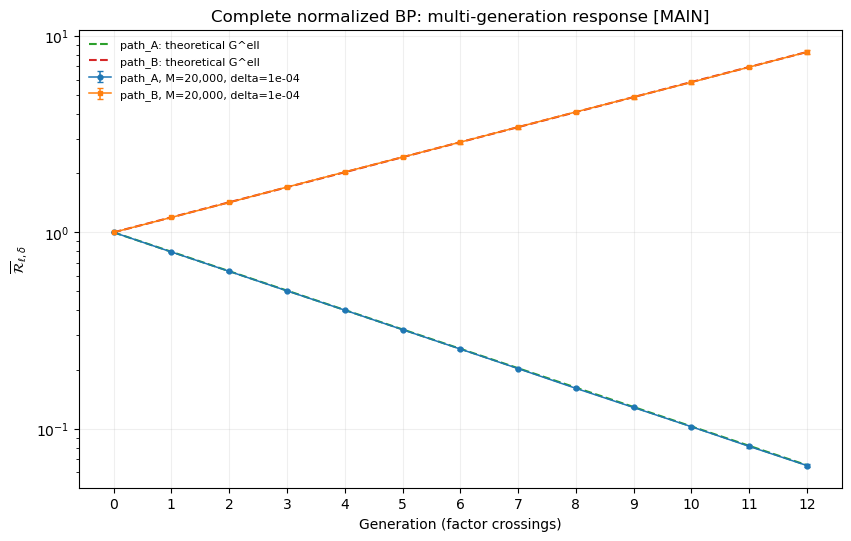

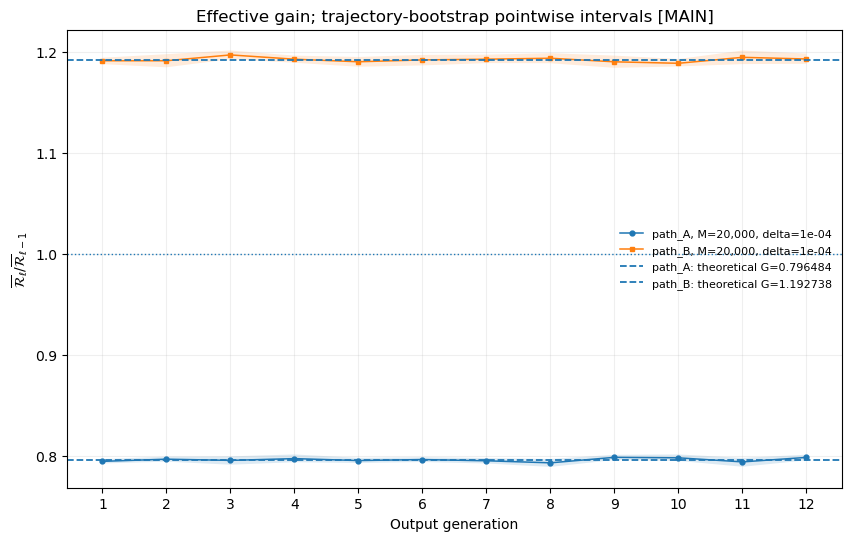

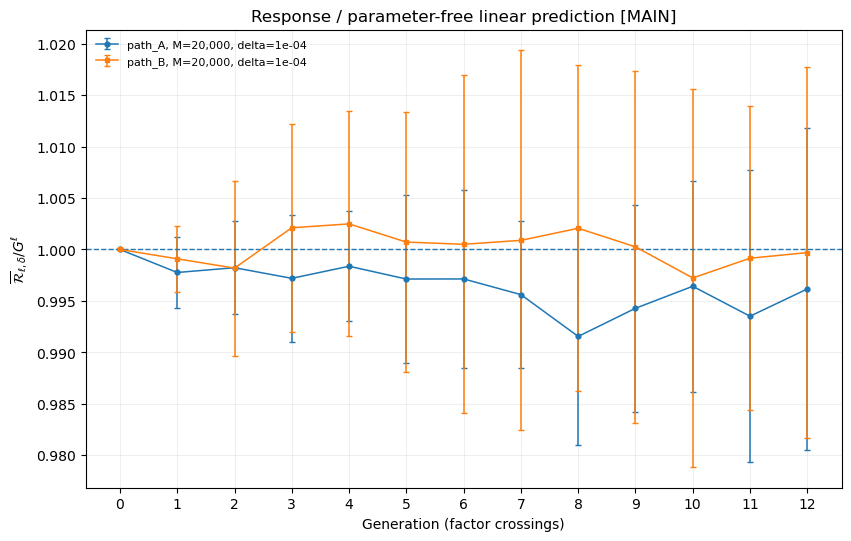

Plots and data: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\bp_growth_validation\multigeneration_cached_main
Intervals are pointwise; small-run bootstrap intervals are exploratory. Population-size bias is not included in these intervals.


In [15]:
show_multigeneration_results(mg_result)


### 8.5 Output files and numerical checks

| File | Contents |
|---|---|
| `manifest.json` | Model, actual sample sizes, planned seeds, status, completed runs and file hashes, environment, and code-object fingerprints |
| `path_A_M..._run00.npz`, etc. | One independent run: responses, diagnostics, and actual incidence counts by depth; optional particlewise squared responses and final complete messages |
| `multigeneration_runs.npz` | `R_runs` with shape `(group, repeat, depth, amplitude)`; groups identify configuration and M |
| `summary.json` | Means, standard deviations, standard errors, pointwise intervals, effective gains, and explicitly labeled theoretical references |
| `measurements.csv` | Mean/error for each group, depth, and amplitude; paired differences from the smallest amplitude |
| `diagnostics.csv` | Midpoint/paired-energy ratio, mean-bias fraction, maximum deviation, and normalization error for each run and depth |

After the main experiment, run `amplitude_check` and `population_check` separately. Check whether smaller amplitudes or larger M change the conclusions; pilot agreement alone does not establish publication-level accuracy. A marked increase in midpoint/paired-energy ratio calls for checking nonlinear effects. Invalid probabilities raise errors rather than triggering clipping or perturbation rescaling.

For custom sizes, set `MG_MODE="custom"` and adjust `MG_CUSTOM_POPULATION`, `MG_CUSTOM_DEPTH`, `MG_CUSTOM_REPEATS`, and `MG_CUSTOM_AMPLITUDES` in the third cell. `PATH_ROOTS` does not affect this experiment.

This publication copy includes the compact numeric plotting data from the completed main experiment, with the original run trajectories and provenance. Full particle/root-response population arrays are not included in the upload package. Actual pilot/main/control status is recorded in directory names, the manifest, and plot titles.